# A pretrained, context-conditioned ftnode field — zero-shot on Duffing

**Question.** The earlier study (`FIM_OOD_analysis.ipynb`) trained one model per system on Duffing, with
and without features from a pretrained ODE foundation model (FIM-ODE). Outside the training data, the
FIM features gave no measurable benefit, free fields diverged, and the structured field
$F(x,u)=A(x)\,(x-g(x,u))$ came to rest at the edge of its bounded equilibrium map.

This notebook tests a small foundation model of our own. A **set encoder** reads a context of measured
trajectories and returns one **system code** $c$; a **head** turns $(x,u,c)$ into a field. The head is
either the structured field with the code as an extra input, $A(x;c)\,(x-g(x,u;c))$, bounded **for every
code**, or a free MLP of the same size. Both are pretrained across a generated family of damped mechanical
systems with **Duffing held out**, then tested **zero-shot** — no gradient step on Duffing — on the three
tests of the earlier study. It asks:

1. Can a pretrained, context-conditioned field identify Duffing from a few measured trajectories, including
   the parts of the state space that the context never visits?
2. Does the structured head behave differently from a free head of the same size?

**Answer in one paragraph.** **Yes, inside the family.** From a context of a few measured $q$
trajectories, with no gradient step on Duffing, both heads recover Duffing's equilibria — two sinks and a
saddle in the right places — and settle essentially every test trajectory of the well that the context
never shows in that well (the earlier study's best: 38 of 320). No pretrained model diverges on any test,
and on the other two tests the pretrained models match the best per-system models of the earlier study.
**The two heads behave alike where pretraining has data and differ far from it:** beyond $|q|=R_g$ the
structured head's restoring force stops growing, so its far-field drift error is four to five times the
free head's, yet both settle about the same number of far-field trajectories in the true well. The
edge-of-box failure of the earlier study does not appear. Two limits: Duffing's neighbours were in the
pretraining family, so this shows identification of a known class of system, not transfer to a new one;
and the structural bound decided no outcome here, because the free head stayed bounded too.

Everything below reads saved results: `runs/fm_v0lite/` (produced by `scripts/fm_pretrain.py`,
`scripts/fm_budget_decision.py` and `scripts/fm_eval_duffing.py`) and, for the earlier study,
`runs/fim_ood/`. No cell trains a model; the field figures rebuild the pretrained models from their
checkpoints on CPU. Run the notebook from the repository root.

In [1]:
import importlib.util, json, math, pathlib, warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch

plt.rcParams["font.family"] = "serif"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.axisbelow": True})
warnings.filterwarnings("ignore", message="Converting a tensor with requires_grad")

ROOT = pathlib.Path.cwd()
RUNS = ROOT / "runs/fm_v0lite"          # the pretraining runs and their zero-shot tests
OOD = ROOT / "runs/fim_ood"             # the earlier per-system study (FIM_OOD_analysis.ipynb)
SPLITS = ["trapped_lobe", "crossing_half", "far_field"]
SPLIT_TITLE = {"trapped_lobe": "Test 1 — trapped lobe",
               "crossing_half": "Test 2 — crossing half",
               "far_field": "Test 3 — far field"}
KS = [4, 8, 16, 64]                     # context sizes: trajectories the encoder reads
H = 0.05

# The pretrained models at the final budget (20,000 steps): two heads x two seeds.
MODELS = {"structured s0": RUNS / "pilot/structured_b20000_s0",
          "structured s1": RUNS / "final/structured_b20000_s1",
          "free s0": RUNS / "pilot/free_b20000_s0",
          "free s1": RUNS / "final/free_b20000_s1"}
MODELS = {m: d for m, d in MODELS.items() if (d / "eval_last.json").exists()}
HEAD = {"structured": "$A(x;c)\\,(x-g(x,u;c))$", "free": "MLP$([x,u,c])$"}

# Okabe-Ito colours, as in the other analysis notebooks: free vs structured.
C_FREE, C_STRUCT, C_TRUTH = "#E69F00", "#0072B2", "k"
head_of = lambda m: m.split()[0]
colour = lambda m: C_STRUCT if head_of(m) == "structured" else C_FREE

# The evaluation script's own helpers (model loading, context data, equilibria).
_spec = importlib.util.spec_from_file_location("fm_eval", ROOT / "scripts/fm_eval_duffing.py")
fm_eval = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(fm_eval)
print("models:", ", ".join(MODELS))

models: structured s0, structured s1, free s0, free s1


## The pretraining family and the held-out plant

Every system in pretraining is a damped particle in a quartic potential, driven by a constant input:

$$\ddot q=-U'(q)-(d_0+d_1q^2)\,\dot q+u,\qquad U(q)=\tfrac14a_4q^4+\tfrac13a_3q^3+\tfrac12a_2q^2,\qquad u\sim\mathcal U[-0.25,0.25].$$

A draw is a **double well** with probability 0.5 ($a_4\sim\log\mathcal U[0.3,2]$, well spacing
$w\sim\mathcal U[0.6,1.5]$, $a_2=-a_4w^2$, asymmetry $a_3=a_4ws$ with $s\sim\mathcal U[-0.3,0.3]$), a
**single well** with probability 0.35 ($a_2\sim\log\mathcal U[0.25,4]$, $a_4\sim\mathcal U[0,2]$, $a_3=0$),
and otherwise **linear**. Damping: $d_0\sim\log\mathcal U[0.03,1]$; with probability 0.3 also a
position-dependent part $d_1\sim\mathcal U[0,0.5]$. All of these systems settle to an equilibrium.

**Duffing is held out.** Duffing is the family member $(a_4,a_3,a_2,d_0,d_1)=(1,0,-1,0.2,0)$. A draw is
rejected and redrawn when **all five** hold: $|a_4-1|<0.25$, $|a_3|<0.15$, $|a_2+1|<0.25$,
$|d_0-0.2|<0.06$, $d_1<0.05$. A draw that differs from Duffing in one parameter only, by more than that
margin, stays in. So the hold-out removes a small box around Duffing, not the double-well class:
the test below asks the model to **identify** a system from a family it knows, not to transfer to a new
kind of system.

**Reproducibility.** Batch $i$ of a run with seed $s$ is a pure function of $(s,\text{stream},i)$
(`numpy.random.SeedSequence` → a CPU `torch.Generator`). The cell below regenerates the first 20,000
parameter draws of the training stream for seed 0.

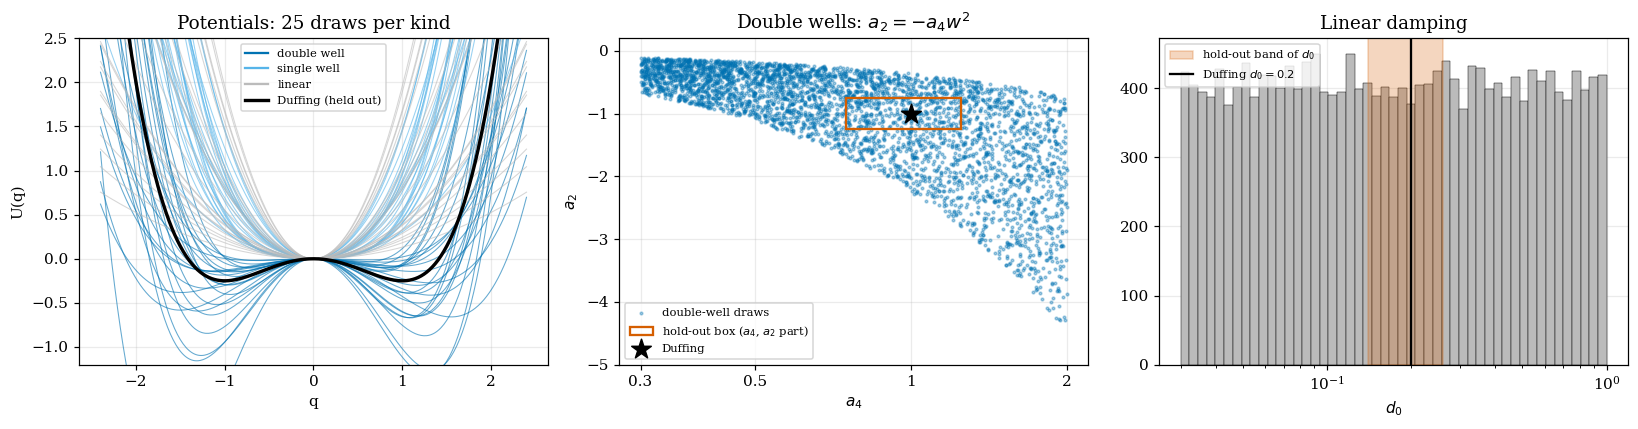

{'double well': '49.9%', 'single well': '34.8%', 'linear': '15.3%'} | inside twice the hold-out box (all five parameters): 4.67% of draws


In [2]:
from ftnode.foundation import (DUFFING_PARAMS, TRAIN_STREAM, MechanicalFamilyConfig,
                               batch_generator, sample_params)

FAM = MechanicalFamilyConfig()
PAR = sample_params(FAM, 20000, batch_generator(0, TRAIN_STREAM, 0)).numpy()
a4, a3, a2, d0, d1 = PAR.T
kind = np.where(a2 < 0, "double well", np.where(a4 > 0, "single well", "linear"))
KIND_COL = {"double well": C_STRUCT, "single well": "#56B4E9", "linear": "#BBBBBB"}

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.0))
q = np.linspace(-2.4, 2.4, 300)
rng = np.random.default_rng(0)
for k, col in KIND_COL.items():
    for i in rng.choice(np.flatnonzero(kind == k), 25, replace=False):
        axes[0].plot(q, a4[i] * q**4 / 4 + a3[i] * q**3 / 3 + a2[i] * q**2 / 2, color=col, lw=0.7, alpha=0.6)
    axes[0].plot([], [], color=col, label=k)
axes[0].plot(q, q**4 / 4 - q**2 / 2, color=C_TRUTH, lw=2.2, label="Duffing (held out)")
axes[0].set_ylim(-1.2, 2.5); axes[0].set_xlabel("q"); axes[0].set_ylabel("U(q)")
axes[0].set_title("Potentials: 25 draws per kind"); axes[0].legend(fontsize=7.5)

dbl = kind == "double well"
axes[1].scatter(a4[dbl][:4000], a2[dbl][:4000], s=3, color=C_STRUCT, alpha=0.35, label="double-well draws")
axes[1].add_patch(plt.Rectangle((0.75, -1.25), 0.5, 0.5, fill=False, ec="#D55E00", lw=1.5,
                                label="hold-out box ($a_4$, $a_2$ part)"))
axes[1].scatter([1], [-1], marker="*", s=180, color=C_TRUTH, zorder=4, label="Duffing")
axes[1].set_xscale("log"); axes[1].set_xticks([0.3, 0.5, 1, 2]); axes[1].set_xticklabels(["0.3", "0.5", "1", "2"])
axes[1].minorticks_off(); axes[1].set_xlabel("$a_4$"); axes[1].set_ylabel("$a_2$")
axes[1].set_ylim(-5, 0.2); axes[1].set_title("Double wells: $a_2=-a_4w^2$")
axes[1].legend(fontsize=7.5, loc="lower left")

axes[2].hist(d0, bins=np.logspace(np.log10(0.03), 0, 50), color="#BBBBBB", edgecolor="k", lw=0.3)
axes[2].axvspan(0.14, 0.26, color="#D55E00", alpha=0.25, label="hold-out band of $d_0$")
axes[2].axvline(0.2, color=C_TRUTH, lw=1.5, label="Duffing $d_0=0.2$")
axes[2].set_xscale("log"); axes[2].set_xlabel("$d_0$"); axes[2].set_title("Linear damping")
axes[2].legend(fontsize=7.5)
plt.tight_layout(); plt.show()

near = ((np.abs(a4 - 1) < 0.5) & (np.abs(a3) < 0.3) & (np.abs(a2 + 1) < 0.5)
        & (np.abs(d0 - 0.2) < 0.12) & (d1 < 0.1))
print({k: f"{(kind == k).mean():.1%}" for k in KIND_COL},
      f"| inside twice the hold-out box (all five parameters): {near.mean():.2%} of draws")

## The model: one code per system, read by the field

A **set encoder** reads the context and returns one system code $c\in\mathbb R^{64}$. A **head** maps
$(x,u,c)$ to the drift. The code is computed once per context and stays fixed during a rollout.

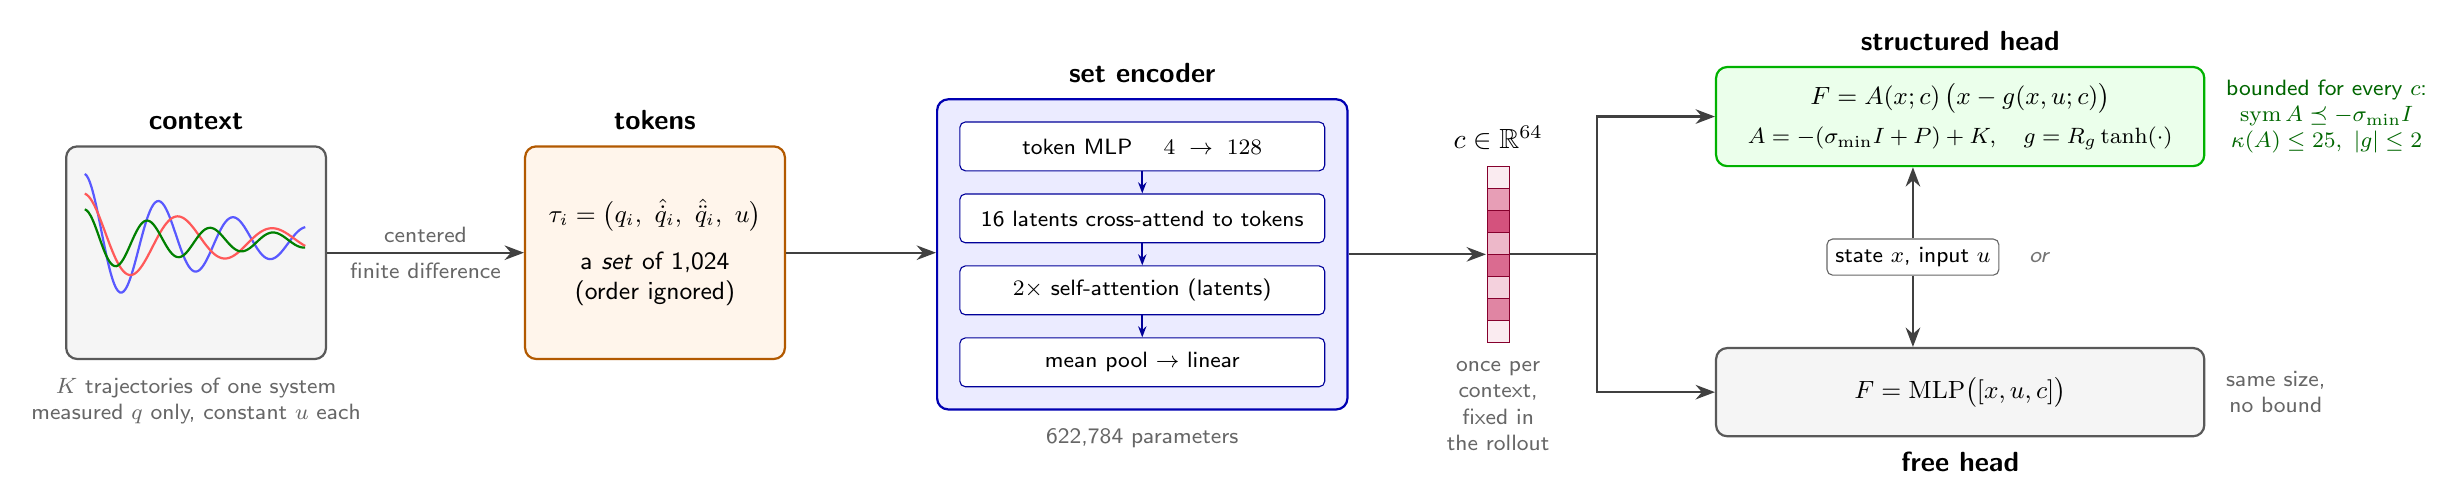

- **Context.** Measured $q$ only. From each of the $K$ context trajectories, central differences give
  tokens $(q,\hat{\dot q},\hat{\ddot q},u)$; 1,024 tokens are drawn at random.
- **Encoder** (622,784 parameters). A token MLP, 16 learned latents that cross-attend to the tokens, two
  self-attention layers, a mean over the latents, and a linear map to $c$. It has no positional encoding, so
  the order of the tokens does not matter: the field of a time-invariant system is a property of the set of
  states it visits, not of their order.
- **Structured head** (38,538 parameters). Today's ftnode field with the code as an extra input:

  $$F(x,u;c)=A(x;c)\,\big(x-g(x,u;c)\big),\quad A=-(\sigma_{\min}I+P)+K,\quad g=R_g\tanh(\cdot).$$

  The networks that build $P$ (symmetric PSD) and $K$ (skew) read $[x,c]$; the network of $g$ reads
  $[x,c,u]$. With $\sigma_{\min}=0.1$, $\kappa(A)\le25$ and $R_g=2$, the bounds
  $\operatorname{sym}A\preceq-\sigma_{\min}I$, $\lVert A\rVert_2\le\sigma_{\max}$ and $g\in[-2,2]^2$ hold
  **for every code $c$**. So no output of the encoder can make a rollout at a fixed code blow up.
- **Free head** (38,554 parameters): $F=\text{MLP}([x,u,c])$, width matched to the structured head.

**Pretraining objective: drift matching with exact labels.** Per system, 256 query states (half on the
context trajectories, half uniform in $|q|\le2$, $|\dot q|\le1.6$) and the true drift $f^\ast$ there:

$$\mathcal L=\operatorname{mean}_{\text{systems}}\;\operatorname{mean}_{\text{queries}}\;\frac{\lVert F(x,u;c)-f^\ast(x,u)\rVert^2}{s_b+0.1},$$

where $s_b$ is the mean squared label on the system's own trajectory queries, so stiff and soft systems
weigh alike. AdamW, learning rate $3\times10^{-4}$, 500 warmup steps, then cosine decay to 5% over the step
budget, 64 systems per step, every system new.

## The training budget — the learning-curve pilot

With every batch new, the model cannot overfit; with a cosine schedule, the stop is the step budget. The
budget came from a pilot: per head, complete schedules of 5,000 steps (two seeds) and 20,000 steps (one
seed), all scored on one fixed validation set of 512 systems. The decision metric is the normalized drift
error at the validation trajectory states (left panel). The box states (middle) include the region
$|q|\le2$ off the trajectories. The Duffing probe (right) is the held-out plant on its standard training box;
it was logged for monitoring only and decided nothing.

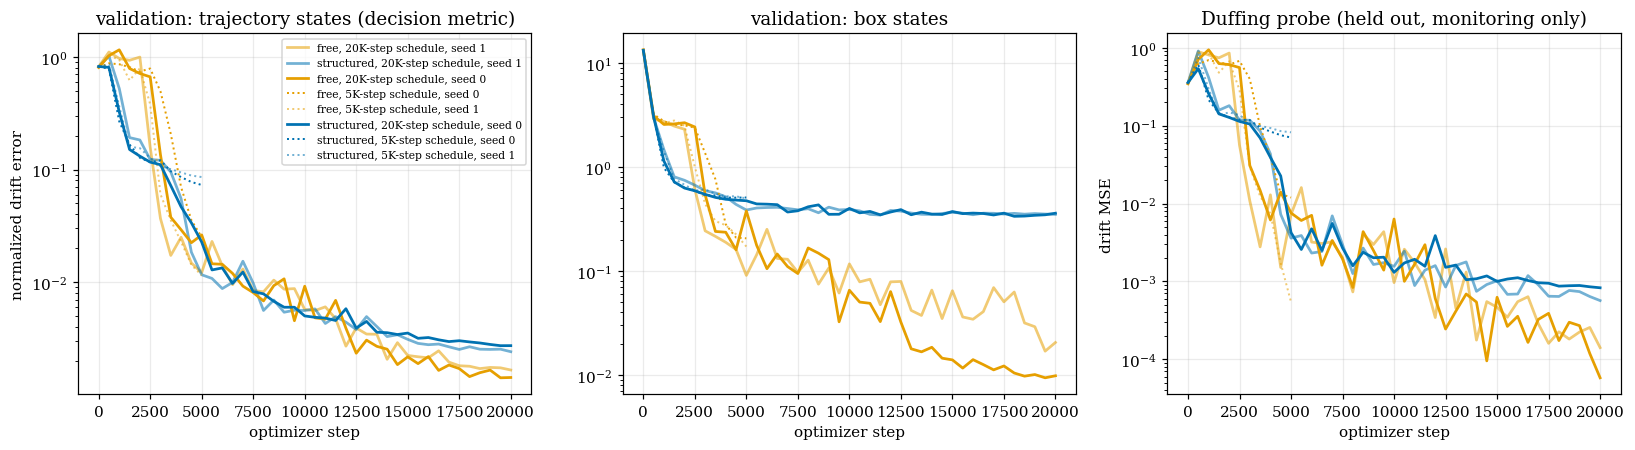

In [3]:
def read_log(d):
    return [json.loads(l) for l in open(d / "log.jsonl")]

RUN_DIRS = sorted(list((RUNS / "pilot").glob("*_b*_s*")) + list((RUNS / "final").glob("*_b*_s*")))
RUN_DIRS = [d for d in RUN_DIRS if (d / "summary.json").exists()]
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.2), sharex=True)
for d in RUN_DIRS:
    head, b, s = d.name.split("_")
    budget, seed = int(b[1:]), int(s[1:])
    L = read_log(d)
    st = [r["step"] for r in L]
    col = C_STRUCT if head == "structured" else C_FREE
    style = dict(ls="-" if budget == 20000 else ":", lw=1.8 if budget == 20000 else 1.3,
                 alpha=1.0 if seed == 0 else 0.55, color=col)
    for ax, key in zip(axes, ["val_traj_rel", "val_box_rel", "duffing_probe_mse"]):
        ax.semilogy(st, [r[key] for r in L], **style,
                    label=f"{head}, {budget // 1000}K-step schedule, seed {seed}")
axes[0].set_title("validation: trajectory states (decision metric)")
axes[1].set_title("validation: box states")
axes[2].set_title("Duffing probe (held out, monitoring only)")
for ax in axes:
    ax.set_xlabel("optimizer step")
axes[0].set_ylabel("normalized drift error")
axes[2].set_ylabel("drift MSE")
axes[0].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

**The budget rule** (agreed before the pilot ran). (1) Each pilot run must stop on its budget, skip at most
1% of steps, and end at least $10\times$ below its step-0 error; a head that fails gets no next stage.
(2) Noise: $\sigma=\max(\sigma_{\text{seed}},SE_\Delta)$ with $\sigma_{\text{seed}}=|v_5^{(0)}-v_5^{(1)}|/\sqrt2$.
(3) Gain $g=\overline{v_5}-v_{20}$: still improving if $g>2\sigma$ (budget 80,000), saturated otherwise
(budget 20,000). (4) Both heads get the larger budget. The table recomputes every number from the run
summaries, and adds the same gain on a log scale.

In [4]:
dec = json.loads((RUNS / "pilot/decision.json").read_text())
rows = []
for head in ("structured", "free"):
    S = {k: json.loads((RUNS / f"pilot/{head}_b{b}_s{s}/summary.json").read_text())
         for k, (b, s) in {"5K s0": (5000, 0), "5K s1": (5000, 1), "20K s0": (20000, 0)}.items()}
    v = {k: r["final"]["val_traj_rel"] for k, r in S.items()}
    se = {k: r["final"]["val_traj_rel_se"] for k, r in S.items()}
    drop = {k: r["first"]["val_traj_rel"] / r["final"]["val_traj_rel"] for k, r in S.items()}
    m5 = (v["5K s0"] + v["5K s1"]) / 2
    s_seed = abs(v["5K s0"] - v["5K s1"]) / math.sqrt(2)
    se_d = math.sqrt((se["5K s0"] ** 2 + se["5K s1"] ** 2) / 4 + se["20K s0"] ** 2)
    sigma = max(s_seed, se_d)
    lv = {k: math.log(x) for k, x in v.items()}
    ls_seed = abs(lv["5K s0"] - lv["5K s1"]) / math.sqrt(2)
    h = dec["heads"][head]
    rows.append({"head": head,
                 "5K s0": f"{v['5K s0']:.4f}", "5K s1": f"{v['5K s1']:.4f}", "20K s0": f"{v['20K s0']:.5f}",
                 "smallest drop (rule: ≥ 10x)": f"{min(drop.values()):.1f}x",
                 "gain / σ (rule)": f"{(m5 - v['20K s0']) / sigma:.2f}",
                 "gain / σ (log scale)": f"{((lv['5K s0'] + lv['5K s1']) / 2 - lv['20K s0']) / ls_seed:.1f}",
                 "mean 5K / 20K": f"{m5 / v['20K s0']:.1f}x",
                 "rule outcome": "failed a check" if not h["pass"] else ("improving" if h["improving"] else "saturated")})
display(pd.DataFrame(rows).set_index("head"))
print("decision: budget", dec["budget"], "| launched:", [(L["head"], L["seeds"]) for L in dec["launch"]])

,5K s0,5K s1,20K s0,smallest drop (rule: ≥ 10x),gain / σ (rule),gain / σ (log scale),mean 5K / 20K,rule outcome
head,,,,,,,,
structured,0.0729,0.0857,0.00273,9.5x,8.46,29.4,29.0x,failed a check
free,0.0251,0.0115,0.00143,32.0x,1.75,4.5,12.8x,saturated


decision: budget 20000 | launched: [('free', [1])]


**Reading.**

1. **The rule chose 20,000 steps, and in two ways it misfired.** The structured 5,000-step seed-1 run
   dropped $9.5\times$, so it missed the $10\times$ sanity check by 5%, while the same head's 20,000-step run
   dropped $300\times$. Had it passed, the structured gain would have been $8.5\sigma$ (still improving) and
   both heads would have trained for 80,000 steps. The free head was called saturated because the noise is
   measured on a linear scale: at 5,000 steps its two seeds differ by $2.2\times$, so $\sigma_{\text{seed}}$ is
   large next to the absolute gain, even though the 20,000-step error is $12.8\times$ lower. On a log scale
   the gain is $4.5\sigma$.
2. **Both heads were still improving at 20,000 steps** (left panel). The models below completed their cosine
   schedule, but they are not converged.
3. **Final models.** 20,000 steps, two seeds per head: the 20,000-step pilot (seed 0) and one more run
   (seed 1) per head. The structured seed-1 run was added by hand after the rule had given the structured
   head no next stage.
4. **The structured box error stops near 0.36** (middle). Off the trajectories the box includes states near
   $|q|=2$ with large cubic forces, and a bounded $g$ cannot follow them. The free head reaches 0.01–0.02.
5. The structured head learns faster at first; the free head has an early instability (seed 0, steps
   1,000–2,500) and then catches up by step 5,000.

## The zero-shot tests

The three tests of the earlier per-system study (`FIM_OOD_analysis.ipynb`), with the same test
trajectories (test seeds 1000–1004, 64 each, 600 steps) and the same scoring. **No model is trained on
Duffing.** For each test, the context is the first $K$ of the test's 64 training trajectories (200 steps,
measured $q$ only); the encoder turns it into one code, and the field is rolled out from the start state of
every test trajectory.

| Test | Context (what the encoder sees) | Test trajectories |
|---|---|---|
| 1 — trapped lobe | the right well only | the left well only |
| 2 — crossing half | starts with $q_0>0$ (about a third cross) | starts with $q_0<0$ |
| 3 — far field | the standard box $[-1.6,1.6]\times[-1,1]$ | starts with $\lvert q_0\rvert\in[2,4]$ |

**Scoring.** Each prediction is sorted by where it settles (mean and spread of $\hat q$ over the last 200
steps), with the bins and tolerances of the earlier study:

| Bin | Rule |
|---|---|
| **true well** | within 0.3 of the true resting place |
| **other well** | within 0.3 of the mirror place (the other well) |
| **settled at q≈0** | at rest (std $\le0.2$) within 0.3 of $q=0$, where the true system has a saddle |
| **edge \|q\|≈2** | at rest within 0.3 of $\lvert q\rvert=2$, the edge of the structured model's equilibrium box |
| **still oscillating** | not at rest and not in either well |
| **other bounded** | bounded, none of the above |
| **diverged** | non-finite, or $\lvert\hat q\rvert>5$ in the last 200 steps |

**The reference.** For each test, the best model of each arm of the earlier study: models trained on
that test's 64 training trajectories of Duffing itself (cold MLP, cold $A(x-g)$), the pretrained FIM-ODE
alone, and FIM with an MLP or $A(x-g)$ head (mean over 5 seeds).

In [5]:
TOL, DIV, OSC = 0.3, 5.0, 0.2
BINS = ["true well", "other well", "settled at q≈0", "edge |q|≈2", "still oscillating", "other bounded", "diverged"]
BIN_COLOR = ["#009E73", "#E69F00", "#CC79A7", "#56B4E9", "#F0E442", "#BBBBBB", "#D55E00"]
IDX = {b: k for k, b in enumerate(BINS)}

def classify(P, Y):
    Pn = np.where(np.isfinite(P), P, np.nan)
    with np.errstate(all="ignore"):
        div = ~np.isfinite(P).all(1) | (np.nanmax(np.abs(Pn[:, 400:]), 1) > DIV)
        lp = np.nanmean(Pn[:, 400:], 1)
        ls = np.nanstd(Pn[:, 400:], 1)
    ly = Y[:, 400:].mean(1)
    rest = ls <= OSC
    b = np.full(len(P), IDX["other bounded"])
    b[~rest] = IDX["still oscillating"]
    b[rest & (np.abs(np.abs(lp) - 2) < TOL)] = IDX["edge |q|≈2"]
    b[rest & (np.abs(lp) < TOL)] = IDX["settled at q≈0"]
    b[np.abs(lp + ly) < TOL] = IDX["other well"]
    b[np.abs(lp - ly) < TOL] = IDX["true well"]
    b[div] = IDX["diverged"]
    return b, lp

# The pretrained models: one prediction file per test and context size.
FM, TRUTH, EVAL = {}, {}, {m: json.loads((d / "eval_last.json").read_text()) for m, d in MODELS.items()}
for split in SPLITS:
    FM[split] = {}
    for m, d in MODELS.items():
        for K in KS:
            z = np.load(d / f"pred_{split}_K{K}.npz")
            P, Y = z["qhat"].astype(np.float64), z["y"].astype(np.float64)
            TRUTH.setdefault(split, Y)
            assert np.array_equal(TRUTH[split], Y)
            b, lp = classify(P, Y)
            FM[split][(m, K)] = dict(counts=np.bincount(b, minlength=len(BINS)), late=lp, P=P[:6])

# The earlier study: the best model of each arm, per test (most predictions in the true well).
OOD_ARM = {"C1": "cold · MLP", "C2": "cold · $A(x-g)$", "Z": "FIM alone", "M": "FIM + MLP", "S": "FIM + $A(x-g)$"}
OODB = {}
for split in SPLITS:
    best = {}
    for cdir in sorted(p for p in (OOD / split).iterdir() if p.is_dir()):
        arm, C, ex, dr = cdir.name.split("-")[0], [], [], []
        for j in sorted(cdir.glob("seed*.npz")):
            z = np.load(j)
            P, Y = z["qhat"].astype(np.float64), z["y"].astype(np.float64)
            assert np.array_equal(Y, TRUTH[split])            # the same test trajectories
            C.append(np.bincount(classify(P, Y)[0], minlength=len(BINS)))
            ex.append(P[:6])
            r = json.loads(j.with_suffix(".json").read_text())
            dr.append((r["drift_mse_train"], r["drift_mse_test"]))
        C = np.array(C)
        k = int(np.argmin(np.abs(C[:, 0] - C[:, 0].mean())))  # the most typical seed
        rec = dict(cell=cdir.name, counts=C.mean(0), P=ex[k], drift=np.mean(dr, 0))
        if arm not in best or rec["counts"][0] > best[arm]["counts"][0]:
            best[arm] = rec
    OODB[split] = best
print("pretrained models:", len(MODELS), "| earlier-study best cells:",
      {s: {a: b["cell"] for a, b in OODB[s].items()} for s in SPLITS})

pretrained models: 4 | earlier-study best cells: {'trapped_lobe': {'C1': 'C1-drift', 'C2': 'C2-drift', 'M': 'M-R1-roll', 'S': 'S-R2-roll', 'Z': 'Z'}, 'crossing_half': {'C1': 'C1-drift', 'C2': 'C2-drift', 'M': 'M-R2-drift', 'S': 'S-R2-drift', 'Z': 'Z'}, 'far_field': {'C1': 'C1-drift', 'C2': 'C2-roll', 'M': 'M-R1-drift', 'S': 'S-R1-drift', 'Z': 'Z'}}


In [6]:
def settle_figure(split, ax):
    rows = [(f"pretrained {m}, K = {K}", FM[split][(m, K)]["counts"]) for m in MODELS for K in KS]
    rows += [(f"earlier study: {OOD_ARM[a]} ({OODB[split][a]['cell']}, 5-seed mean)", OODB[split][a]["counts"])
             for a in OOD_ARM]
    y = np.arange(len(rows))[::-1]
    left = np.zeros(len(rows))
    for k, (name, col) in enumerate(zip(BINS, BIN_COLOR)):
        v = np.array([c[k] for _, c in rows])
        ax.barh(y, v, left=left, color=col, edgecolor="k", lw=0.3, label=name)
        left += v
    for yi, (_, c) in zip(y, rows):
        ax.text(322, yi, f"{c[0]:.0f}", va="center", fontsize=7)
    ax.set_yticks(y); ax.set_yticklabels([n for n, _ in rows], fontsize=7.5)
    for i in range(1, len(MODELS) + 1):
        ax.axhline(len(rows) - 0.5 - i * len(KS), color="k", lw=0.8 if i == len(MODELS) else 0.4)
    ax.set_xlim(0, 345); ax.set_xlabel("test trajectories (of 320)")
    ax.set_title(SPLIT_TITLE[split] + " — where the predictions settle  (number = true well)")
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.35, -0.09), ncol=7, frameon=False)

## Test 1 — trapped lobe: the context shows the right well, the test is the left well

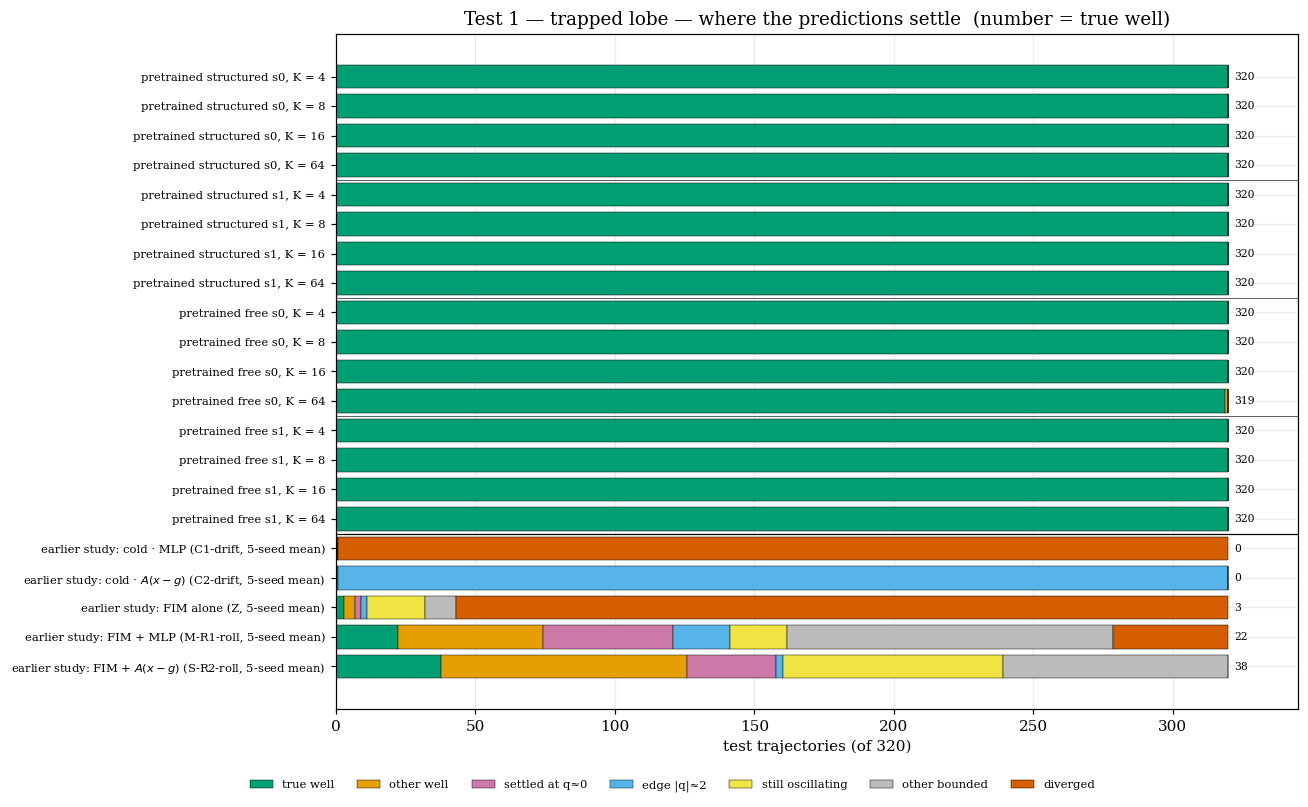

In [7]:
fig, ax = plt.subplots(figsize=(12.0, 7.4))
settle_figure("trapped_lobe", ax)
plt.tight_layout(); plt.show()

**Reading.**

1. **Every pretrained model puts the test trajectories in the unseen left well** — 320 of 320 for every
   model at every context size, except one run at $K=64$ (319). The context shows only the right well. In the earlier study, the best model sent 38 of 320 there,
   every cold free field diverged, and every cold structured field came to rest at the edge $q=-R_g=-2$.
2. **The prior comes from the family.** The pretraining family contains many double wells, so a context
   from one well is enough to pick a field that has the second well and the saddle in the right places
   (see the phase portraits below). The encoder identifies a family member; it does not have to extrapolate.
3. **No structured model rests at the edge of its equilibrium box.** Pretraining covers $|q|\le2$ with
   data, so $g$ is not left to saturate there.

## Test 2 — crossing half: context from $q_0>0$, test from $q_0<0$

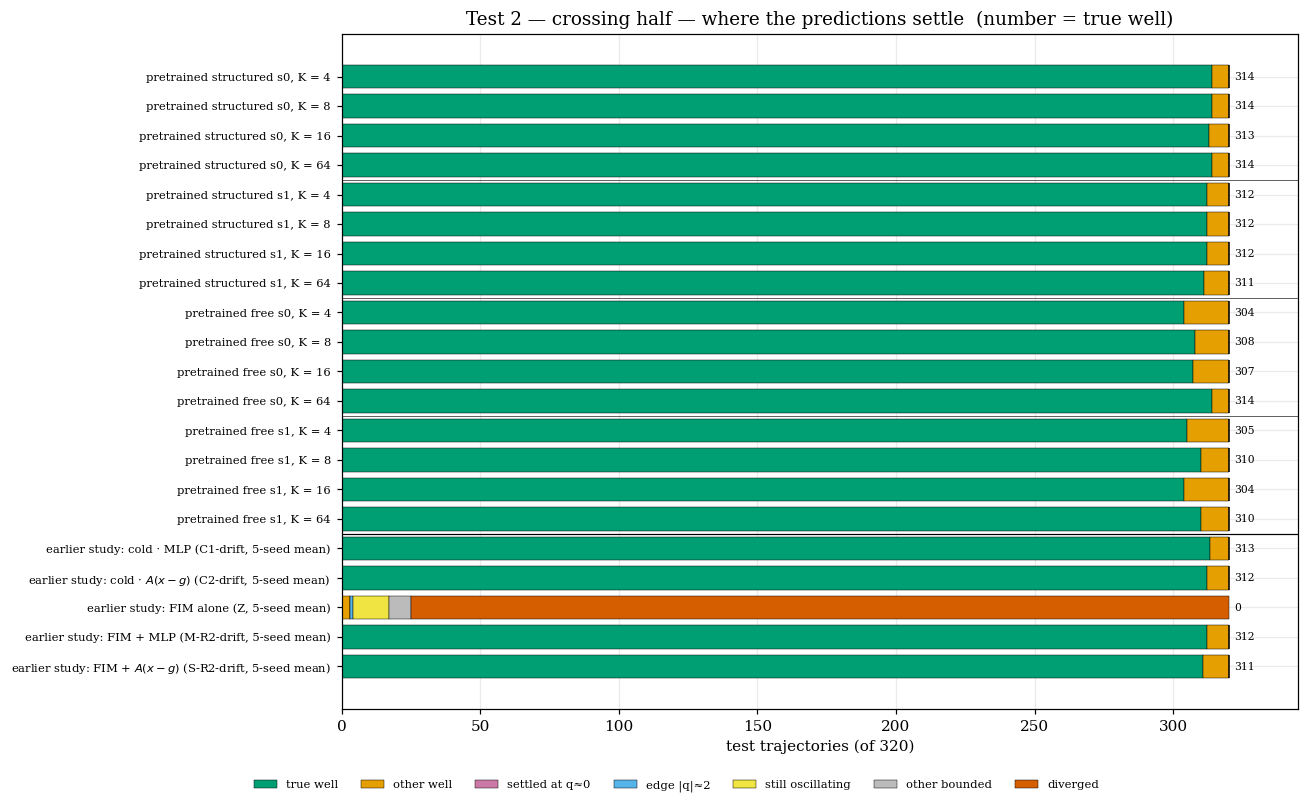

In [8]:
fig, ax = plt.subplots(figsize=(12.0, 7.4))
settle_figure("crossing_half", ax)
plt.tight_layout(); plt.show()

**Reading.** Close to in-distribution: the context reaches the left well through the trajectories that
cross. The structured models settle 311–314 of 320 in the true well at every $K$; the free models 304–314.
The best model of the earlier study, a cold MLP trained on this data, settles 313. The free head's extra
errors are trajectories that **stay** in the left well but are predicted to cross: 5–14 per run, against
0–5 for the structured head, which errs mostly on trajectories that really cross, where the true outcome
depends on a small difference in energy.

## Test 3 — far field: context from the standard box, test from $|q_0|\in[2,4]$

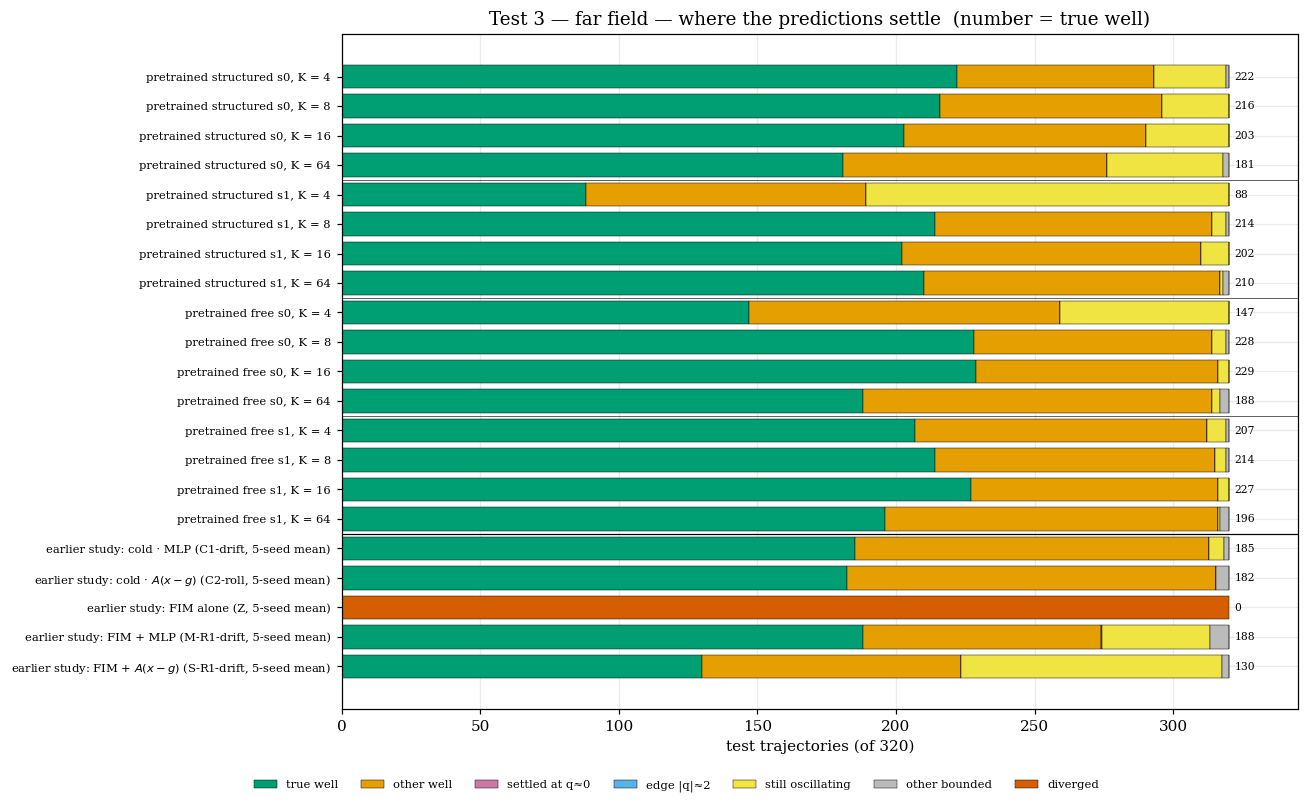

In [9]:
fig, ax = plt.subplots(figsize=(12.0, 7.4))
settle_figure("far_field", ax)
plt.tight_layout(); plt.show()

**Reading.**

1. **The well counts are alike across models** — at $K\ge8$, 181–216 for the structured head and 188–229
   for the free head — and close to the best model of the earlier study (188). From a high-energy start the
   truth settles about half in each well, and the well it picks is sensitive to the start.
2. **$K=4$ is not enough here.** One run of each head drops: structured seed 1 to 88 (131 still
   oscillating), free seed 0 to 147 (61 still oscillating).
3. **No model diverges**, structured or free.
4. **The structured restoring force stops growing beyond $|q|=2$** (see the force figure below), and its
   drift error on the test states is about 4, against 0.7–0.9 for the free head. One structured seed (s0)
   keeps 24–42 trajectories oscillating at $K\ge8$ and swings wider than the truth (see the examples); the
   other (s1) keeps 1–10, like the free head (1–5). So the force ceiling costs drift accuracy far out, but
   by itself it does not decide where the trajectories settle.

## Example predictions

The first three test trajectories of each test. Black dashed: the truth. Blue and orange: the pretrained
structured and free models (seed 0) with a context of $K=16$ trajectories. Grey: the best model of the
earlier study on that test (its most typical seed).

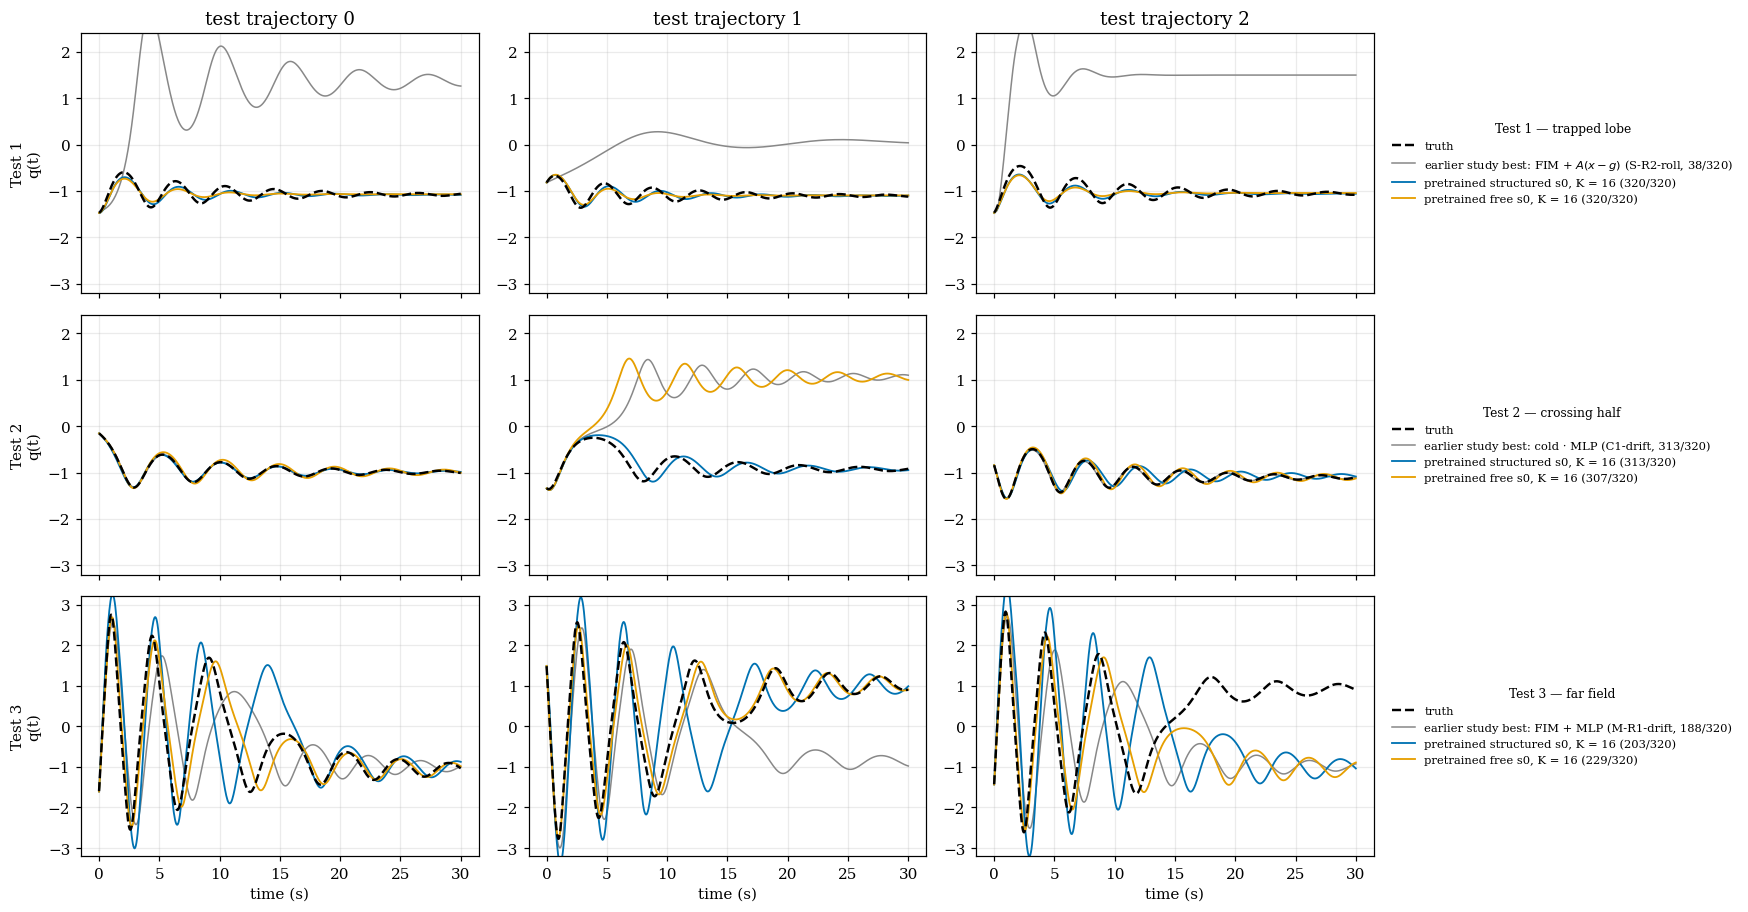

In [10]:
t = np.arange(601) * H
fig, axes = plt.subplots(3, 3, figsize=(16.0, 8.4), sharex=True)
for row, split in enumerate(SPLITS):
    arm = max(OODB[split], key=lambda a: OODB[split][a]["counts"][0])
    ref = OODB[split][arm]
    for j in range(3):
        ax = axes[row, j]
        ax.plot(t, TRUTH[split][j], "--", color=C_TRUTH, lw=1.6, label="truth", zorder=5)
        ax.plot(t, ref["P"][j], color="#888888", lw=1.0,
                label=f"earlier study best: {OOD_ARM[arm]} ({ref['cell']}, {ref['counts'][0]:.0f}/320)")
        for m in [m for m in MODELS if m.endswith("s0")]:
            ax.plot(t, FM[split][(m, 16)]["P"][j], color=colour(m), lw=1.2,
                    label=f"pretrained {m}, K = 16 ({FM[split][(m, 16)]['counts'][0]}/320)")
        ax.set_ylim(-3.2, 3.2 if split == "far_field" else 2.4)
        if j == 0:
            ax.set_ylabel(SPLIT_TITLE[split].split(" — ")[0] + "\nq(t)")
        if row == 0:
            ax.set_title(f"test trajectory {j}")
    axes[row, 2].legend(fontsize=7.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
                        title=SPLIT_TITLE[split], title_fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
plt.tight_layout(); plt.show()

## How much context is needed

Predictions in the true well against the number of context trajectories $K$. The dashed line is the best
model of the earlier study on that test (any arm), trained on all 64 training trajectories.

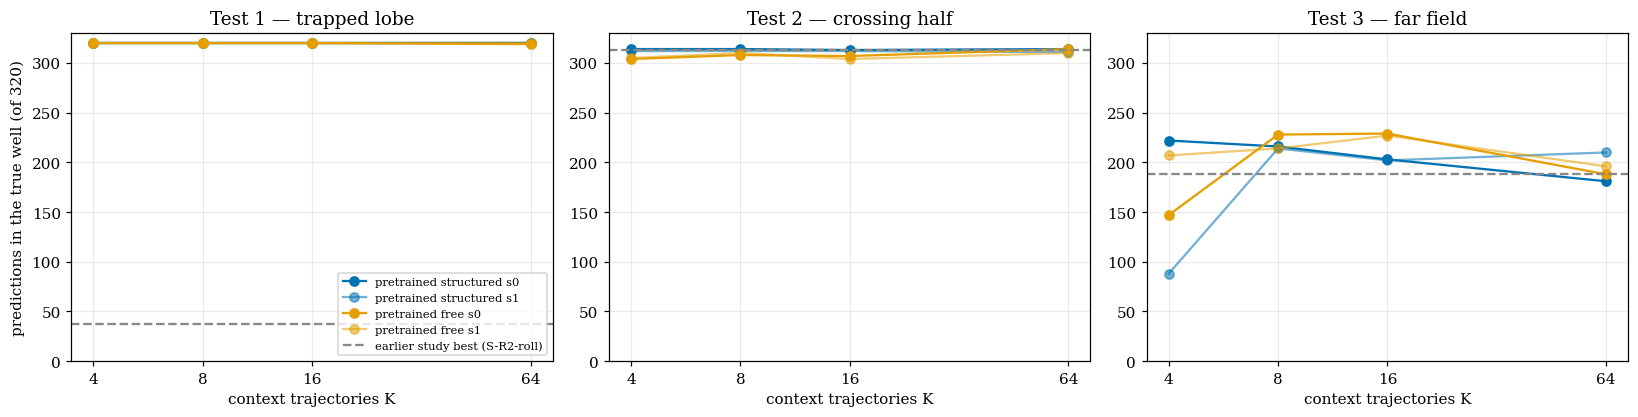

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15.0, 3.9))
for ax, split in zip(axes, SPLITS):
    for m in MODELS:
        ax.plot(KS, [FM[split][(m, K)]["counts"][0] for K in KS], "o-", color=colour(m),
                alpha=1.0 if m.endswith("s0") else 0.55, label=f"pretrained {m}")
    arm = max(OODB[split], key=lambda a: OODB[split][a]["counts"][0])
    ax.axhline(OODB[split][arm]["counts"][0], ls="--", color="#888888",
               label=f"earlier study best ({OODB[split][arm]['cell']})")
    ax.set_xscale("log", base=2); ax.set_xticks(KS); ax.set_xticklabels(KS)
    ax.set_ylim(0, 330); ax.set_xlabel("context trajectories K"); ax.set_title(SPLIT_TITLE[split])
axes[0].set_ylabel("predictions in the true well (of 320)")
axes[0].legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.show()

**Reading.** A few trajectories are enough. On tests 1 and 2 the count barely moves with $K$. On test 3,
$K=4$ is not reliable (one run of each head drops, to 88 and 147), and $K=64$ is below $K=16$ for three of
the four models. One possible cause: the context has a fixed 1,024 tokens, so at $K=64$ each trajectory
gives only 16. With two seeds per head this is a pattern, not yet a measured effect.

## What the field looks like

The fields are rebuilt from the saved checkpoints and bound to a context, exactly as in the test.

**Phase portraits, test 1.** The context is the 64 right-well training trajectories (orange); the encoder
never sees the left well. Shown at $u=0$, with the equilibria that Newton's method finds from
$(-1,0)$, $(0,0)$ and $(1,0)$ (circle = sink, X = saddle).

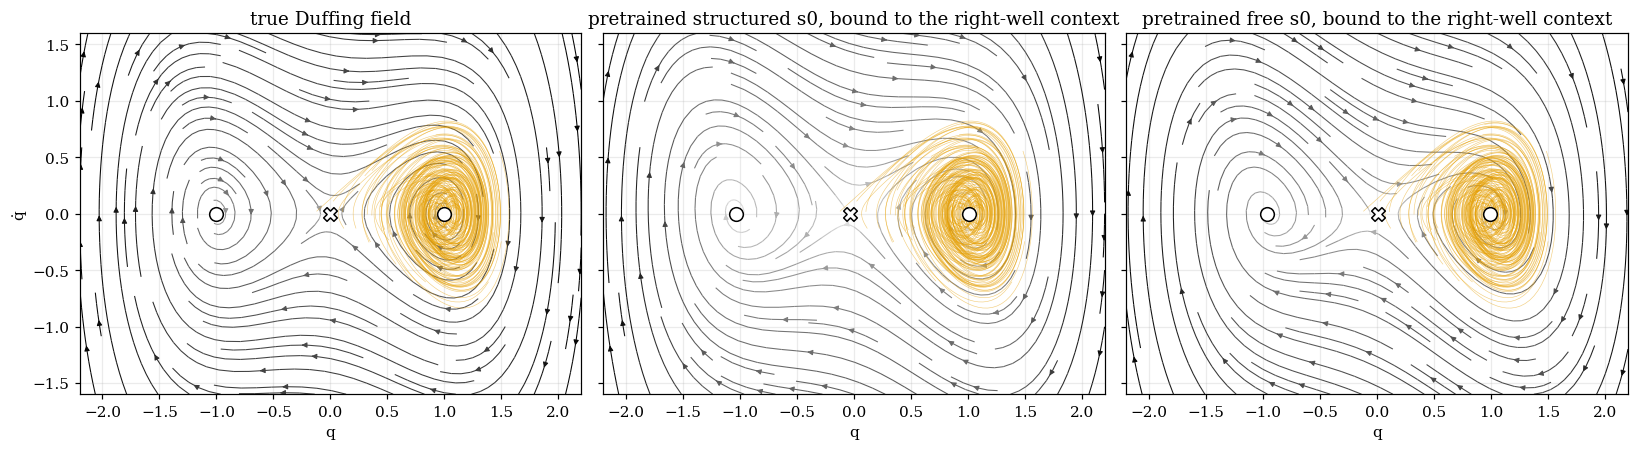

In [12]:
FIELDS = {m: fm_eval.load(d, "last.pt", "cpu")[0] for m, d in MODELS.items()}

def bind(field, split, K=64):
    train = fm_eval.train_data(fm_eval.SPLITS[split][0], max(KS))
    q_all = torch.cat([train.W, train.Y], 1)
    tokens = fm_eval.tokens_from_q(q_all[:K], train.U[:K], H, n_tok=1024,
                                   generator=fm_eval.batch_generator(7, 2, K))
    with torch.no_grad():
        field.bind_context(tokens)
    return train

def duffing(x, u=0.0):
    q, v = x[..., 0], x[..., 1]
    return np.stack([v, -0.2 * v - q**3 + q + u], -1)

qq, vv = np.meshgrid(np.linspace(-2.2, 2.2, 41), np.linspace(-1.6, 1.6, 33))
X = np.stack([qq, vv], -1)
show = ["truth"] + [m for m in MODELS if m.endswith("s0")]
fig, axes = plt.subplots(1, len(show), figsize=(5.0 * len(show), 4.2), sharey=True)
for ax, m in zip(axes, show):
    if m == "truth":
        Fv = duffing(X)
        eq = [(-1, "sink"), (0, "saddle"), (1, "sink")]
        train = fm_eval.train_data(fm_eval.SPLITS["trapped_lobe"][0], max(KS))
    else:
        train = bind(FIELDS[m], "trapped_lobe")
        with torch.no_grad():
            Fv = FIELDS[m].F(torch.tensor(X.reshape(-1, 2), dtype=torch.float32),
                             torch.zeros(X.size // 2)).numpy().reshape(X.shape)
        eq = [(e["x"][0], e["kind"]) for e in fm_eval.classify_equilibria(FIELDS[m], "cpu") if e["u"] == 0.0]
    speed = np.hypot(Fv[..., 0], Fv[..., 1])
    ax.streamplot(qq, vv, Fv[..., 0], Fv[..., 1], color=np.log(speed + 1e-3), cmap="Greys", density=1.1,
                  linewidth=0.7, arrowsize=0.7)
    for i in range(len(train.Xfull)):
        ax.plot(train.Xfull[i, :, 0], train.Xfull[i, :, 1], color=C_FREE, lw=0.4, alpha=0.5)
    for qe, k in eq:
        ax.scatter([qe], [0], marker="o" if k == "sink" else "X", s=80, color="w", edgecolor="k", zorder=5)
    ax.set_title("true Duffing field" if m == "truth" else f"pretrained {m}, bound to the right-well context")
    ax.set_xlabel("q"); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-1.6, 1.6)
axes[0].set_ylabel("q̇")
plt.tight_layout(); plt.show()

**The restoring force far from the context.** The acceleration $F_2(q,0;u=0)$ along the $q$ axis, against
the true $q-q^3$, with the context of test 3 (the standard box, $|q|\le1.6$). The dotted lines mark
$|q|=R_g=2$. Outside the box of $g$, the structured field $A(x)(x-g)$ grows at most linearly in $|x|$
(since $\lVert A\rVert_2\le\sigma_{\max}$ and $|g|\le R_g$), so it cannot follow a cubic force.

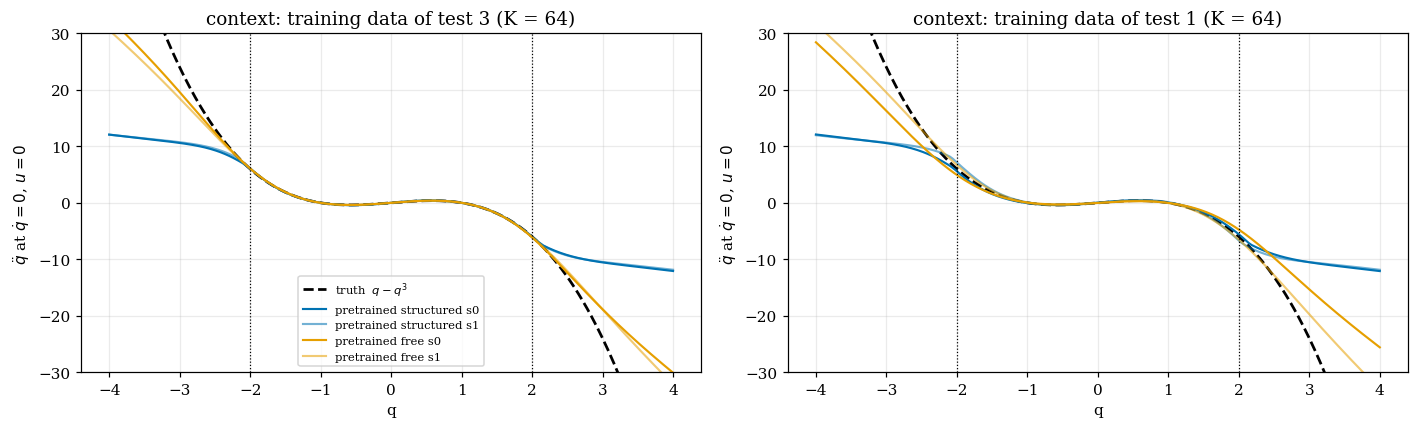

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.0))
qline = np.linspace(-4, 4, 401)
xs = torch.tensor(np.stack([qline, np.zeros_like(qline)], -1), dtype=torch.float32)
for ax, split in zip(axes, ["far_field", "trapped_lobe"]):
    ax.plot(qline, qline - qline**3, "--", color=C_TRUTH, lw=1.8, label="truth  $q-q^3$")
    for m, field in FIELDS.items():
        bind(field, split)
        with torch.no_grad():
            a = field.F(xs, torch.zeros(len(xs)))[:, 1].numpy()
        ax.plot(qline, a, color=colour(m), lw=1.4, alpha=1.0 if m.endswith("s0") else 0.55, label=f"pretrained {m}")
    for s in (-2, 2):
        ax.axvline(s, ls=":", color="k", lw=0.8)
    ax.set_ylim(-30, 30); ax.set_xlabel("q"); ax.set_ylabel("$\\ddot q$ at $\\dot q=0$, $u=0$")
    ax.set_title(f"context: training data of {SPLIT_TITLE[split].split(' — ')[0].lower()} (K = 64)")
axes[0].legend(fontsize=7.5)
plt.tight_layout(); plt.show()

## The equilibria

At the largest context ($K=64$), Newton's method from $(-1,0)$, $(q_s(u),0)$ and $(1,0)$ for
$u\in\{-0.2,0,0.2\}$ (9 points per model and test), then the eigenvalues of $D_xF$. The truth: two sinks with
eigenvalues $-0.1\pm i\sqrt{3q_e^2-1.01}$ and a saddle. The columns are means over the three inputs.

In [14]:
def true_eq(u):
    roots = np.sort(np.roots([1, 0, -1, -u]).real)
    out = {}
    for name, qe in zip(("left", "saddle", "right"), roots):
        ev = np.linalg.eigvals(np.array([[0, 1], [1 - 3 * qe**2, -0.2]]))
        out[name] = (qe, ev)
    return out

rows = []
for m, E in EVAL.items():
    for split in SPLITS:
        eqs = E["splits"][split]["K64"]["equilibria"]
        R = []
        for e in eqs:
            qe, ev = true_eq(e["u"])[e["start"]]
            want = "saddle" if e["start"] == "saddle" else "sink"
            R.append(dict(ok=e["kind"] == want, dq=abs(e["x"][0] - qe), saddle=e["start"] == "saddle",
                          re=e["max_re"], re_t=ev.real.max(), im=max(abs(z[1]) for z in e["eig"]),
                          im_t=np.abs(ev.imag).max()))
        sk, sd = [r for r in R if not r["saddle"]], [r for r in R if r["saddle"]]
        rows.append({"model": m, "test": SPLIT_TITLE[split].split(" — ")[1],
                     "kinds correct (of 9)": sum(r["ok"] for r in R),
                     "max |q error|": f"{max(r['dq'] for r in R):.3f}",
                     "sink Re (true)": f"{np.mean([r['re'] for r in sk]):+.3f} ({np.mean([r['re_t'] for r in sk]):+.3f})",
                     "sink |Im| (true)": f"{np.mean([r['im'] for r in sk]):.3f} ({np.mean([r['im_t'] for r in sk]):.3f})",
                     "saddle unstable eig. (true)": f"{np.mean([r['re'] for r in sd]):.3f} ({np.mean([r['re_t'] for r in sd]):.3f})"})
display(pd.DataFrame(rows).set_index(["model", "test"]))

kinds correct (of 9) max |q error|  \
model         test                                                
structured s0 trapped lobe                      9         0.061   
              crossing half                     9         0.019   
              far field                         9         0.018   
structured s1 trapped lobe                      9         0.104   
              crossing half                     9         0.022   
              far field                         9         0.022   
free s0       trapped lobe                      9         0.084   
              crossing half                     9         0.005   
              far field                         9         0.004   
free s1       trapped lobe                      9         0.028   
              crossing half                     9         0.025   
              far field                         9         0.028   

                              sink Re (true) sink |Im| (true)  \
model         test                                              
structured s0 trapped lobe   -0.174 (-0.100)    1.287 (1.383)   
              crossing half  -0.093 (-0.100)    1.338 (1.383)   
              far field      -0.098 (-0.100)    1.347 (1.383)   
structured s1 trapped lobe   -0.185 (-0.100)    1.475 (1.383)   
              crossing half  -0.099 (-0.100)    1.376 (1.383)   
              far field      -0.106 (-0.100)    1.378 (1.383)   
free s0       trapped lobe   -0.247 (-0.100)    1.147 (1.383)   
              crossing half  -0.094 (-0.100)    1.383 (1.383)   
              far field      -0.097 (-0.100)    1.382 (1.383)   
free s1       trapped lobe   -0.184 (-0.100)    1.404 (1.383)   
              crossing half  -0.087 (-0.100)    1.370 (1.383)   
              far field      -0.095 (-0.100)    1.368 (1.383)   

                            saddle unstable eig. (true)  
model         test                                       
structured s0 trapped lobe                0.898 (0.860)  
              crossing half               1.030 (0.860)  
              far field                   1.018 (0.860)  
structured s1 trapped lobe                0.957 (0.860)  
              crossing half               0.943 (0.860)  
              far field                   0.937 (0.860)  
free s0       trapped lobe                0.582 (0.860)  
              crossing half               0.866 (0.860)  
              far field                   0.861 (0.860)  
free s1       trapped lobe                0.819 (0.860)  
              crossing half               0.832 (0.860)  
              far field                   0.813 (0.860)

**Reading.**

1. **Every model has the right equilibrium set on every test**: two sinks and a saddle, all 9 points of the
   right kind, positions within 0.03 of the truth on tests 2 and 3 and within 0.11 on test 1.
2. **Tests 2 and 3: the local dynamics are right.** The sink damping is within 0.015 of the true $-0.100$,
   and the oscillation frequency within 0.05.
3. **Test 1: the sinks are over-damped** (real part $-0.17$ to $-0.25$ against $-0.100$), the right well that the
   context shows as much as the left well. So the context of test 1 — small oscillations inside one well —
   identifies the damping less well than the wider contexts of tests 2 and 3.

## Fitting the context region against extrapolating

Drift error against the true field on the 64 training trajectories of the test (horizontal) and on the test
trajectories (vertical). Grey: every model of the earlier study (mean over seeds; filled = drift matching,
open = short rollout, distillation, or FIM alone). Stars: the pretrained models with $K=64$, which read the same 64 trajectories as
context but were never trained on them.

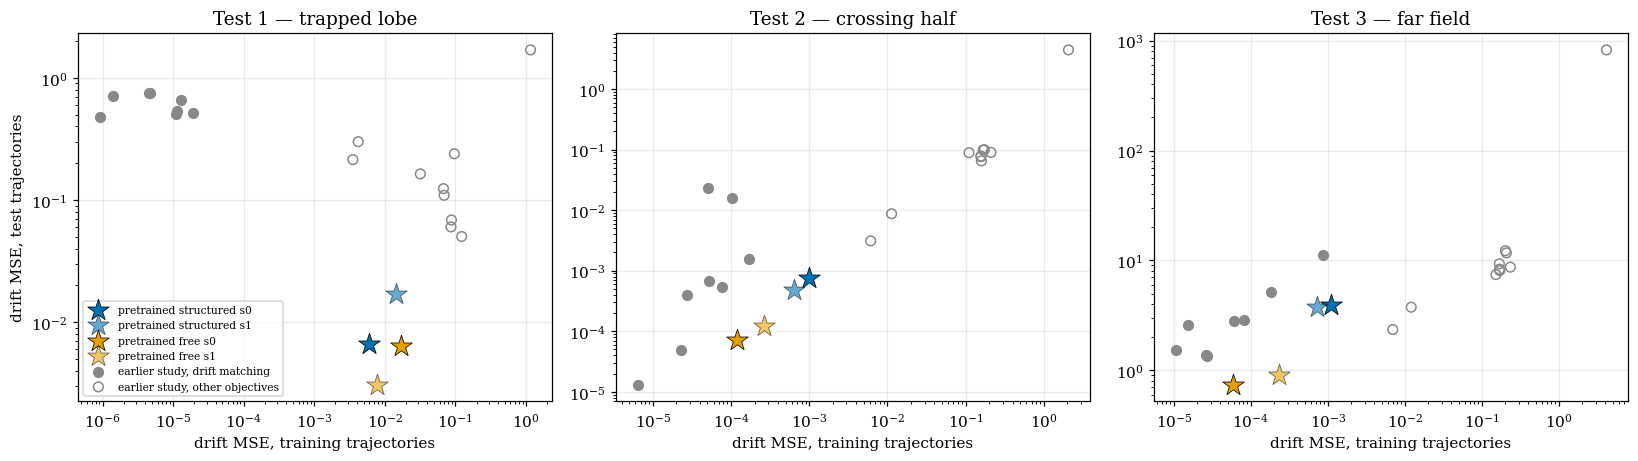

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.3))
for ax, split in zip(axes, SPLITS):
    for cdir in sorted(p for p in (OOD / split).iterdir() if p.is_dir()):
        dr = np.mean([(r["drift_mse_train"], r["drift_mse_test"]) for r in
                      (json.loads(j.read_text()) for j in sorted(cdir.glob("seed*.json")))], 0)
        filled = cdir.name.endswith("drift")
        ax.scatter(*dr, s=40, facecolor="#888888" if filled else "none", edgecolor="#888888", lw=1.0)
    for m, E in EVAL.items():
        r = E["splits"][split]["K64"]
        ax.scatter(r["drift_mse_train_states"], r["drift_mse_test_states"], marker="*", s=220,
                   color=colour(m), edgecolor="k", lw=0.5, alpha=1.0 if m.endswith("s0") else 0.6,
                   label=f"pretrained {m}", zorder=4)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("drift MSE, training trajectories"); ax.set_title(SPLIT_TITLE[split])
axes[0].set_ylabel("drift MSE, test trajectories")
axes[0].scatter([], [], s=40, color="#888888", label="earlier study, drift matching")
axes[0].scatter([], [], s=40, facecolor="none", edgecolor="#888888", label="earlier study, other objectives")
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

**Reading.**

1. **On test 1 the pretrained models' drift error on the test trajectories is 3 to 16 times lower than the
   lowest of the earlier study** (0.003–0.017 against 0.050), though every model there was trained on this
   context data.
2. **On the training trajectories they are mostly less exact than a drift-matched model trained on that
   data** ($6\times10^{-5}$–$2\times10^{-2}$ against $10^{-6}$–$10^{-3}$). Pretraining fits the family; no
   gradient step uses Duffing. On test 2, where the training data reach the test region, a cold MLP
   drift-matched to the data is also more exact on the test trajectories ($1.3\times10^{-5}$ against
   $10^{-4}$–$8\times10^{-4}$).
3. **On test 3 the free pretrained models have the lowest test error of all models; the structured ones do
   not** (0.74–0.91 against 3.8–4.0; the earlier study's lowest is 1.35). The structured error comes from the
   force ceiling outside $|q|=2$. The well counts of the two heads are still alike.

## Across the three tests

In [16]:
rows = []
for split in SPLITS:
    row = {"test": SPLIT_TITLE[split]}
    for head in ("structured", "free"):
        ms = [m for m in MODELS if head_of(m) == head]
        row[f"pretrained {head}: true well, K = 4/8/16/64 (seed mean)"] = " / ".join(
            f"{np.mean([FM[split][(m, K)]['counts'][0] for m in ms]):.0f}" for K in KS)
    row["pretrained: diverged (max)"] = max(FM[split][k]["counts"][IDX["diverged"]] for k in FM[split])
    for grp, arms in [("earlier study, best cold", ("C1", "C2")), ("earlier study, best FIM", ("Z", "M", "S"))]:
        a = max(arms, key=lambda a: OODB[split][a]["counts"][0])
        row[grp] = f"{OODB[split][a]['counts'][0]:.0f} ({OODB[split][a]['cell']})"
    rows.append(row)
display(pd.DataFrame(rows).set_index("test"))

,"pretrained structured: true well, K = 4/8/16/64 (seed mean)","pretrained free: true well, K = 4/8/16/64 (seed mean)",pretrained: diverged (max),"earlier study, best cold","earlier study, best FIM"
test,,,,,
Test 1 — trapped lobe,320 / 320 / 320 / 320,320 / 320 / 320 / 320,0,0 (C1-drift),38 (S-R2-roll)
Test 2 — crossing half,313 / 313 / 312 / 312,304 / 309 / 306 / 312,0,313 (C1-drift),312 (M-R2-drift)
Test 3 — far field,155 / 215 / 202 / 196,177 / 221 / 228 / 192,0,185 (C1-drift),188 (M-R1-drift)


## Caveats

- **The test is inside the family.** Duffing is held out only by a small box around its parameters, and
  about 4.7% of the pretraining draws lie within twice that box. The result shows that the encoder can
  identify a system of a known class from a short context. It does not show transfer to a new class of
  system; that needs a target outside the polynomial-potential family.
- **Two seeds per head, 20,000 steps, not converged.** The budget rule misfired (see above); a longer
  schedule may change the head comparison.
- **One context per test and size**: the first $K$ of the earlier study's 64 training trajectories (data
  seed 0), with one random draw of 1,024 tokens (token seed 7).
- **The bound of the structured head decided nothing here.** The free head did not diverge either. The
  guarantee matters when the context, or the code, is far from what pretraining covered — a regime these
  tests do not reach.

## Summary

- **Zero-shot identification works inside the family.** From measured $q$ only, both heads recover
  Duffing's equilibria and send essentially every test trajectory of the unseen well to that well (earlier
  study: 38 of 320). No pretrained model diverges on any test.
- **Structured against free: alike where the data are, different far away.** On test 2 the structured head
  makes slightly fewer wrong-well errors. On test 3 its force stops growing beyond $|q|=R_g$, which costs
  drift accuracy far out (error about 4 against 0.7–0.9), yet the well counts are alike.
- **The edge-of-box failure of the earlier study does not appear.** It came from a region without data;
  pretraining covers that region.
- **Next:** a target outside the family, and the head choices that set the far-field force (a potential
  head with a coercive $H$).